# CNN 第2週 — CIFAR-10でCNNの性能を改善しよう
## PyTorch：改善方法を1つずつ追加し、Validation性能を比較する

第1週では、MNISTを使ってCNNと5-Fold Cross Validationの基本を学びました。

第2週では、より難しいカラー画像データである **CIFAR-10** を使い、
CNNの性能を高める代表的な方法を、次の順番で1つずつ追加します。

1. Baseline CNN
2. Convolution Layerを追加
3. Data Augmentationを追加
4. Batch Normalizationを追加
5. Dropoutを追加
6. Weight Decayを追加

各段階で同じTrain / Validation分割を使い、

- Train Loss
- Train Accuracy
- Validation Loss
- Validation Accuracy

を比較します。

> 改善手法を追加すれば、必ず毎回Accuracyが上がるとは限りません。  
> 学習回数、乱数、モデルの大きさ、過学習などによって結果は変わります。  
> 「なぜ変化したのか」を考えることが、この実習の目的です。


## この実習で学ぶこと

- MNISTとCIFAR-10の違い
- RGB画像のTensor shape
- Baseline CNNの作成
- Convolution Layerを増やす意味
- Data Augmentationの役割
- Batch Normalizationの役割
- Dropoutの役割
- Weight Decayの役割
- TrainとValidationの曲線の読み方
- Validation結果でモデルを選び、Testは最後に1回だけ評価する方法

### 今回は5-Foldを行わない理由

6種類のモデルをそれぞれ5回学習すると、授業時間内に終わりにくいためです。

今回は、すべての実験で **同じTrain / Validation分割** を使い、
CNNの改善方法による変化を比較します。


# PART 1 — 実行環境とライブラリ

## 1. GPUを確認する

CIFAR-10で複数のCNNを学習するため、GPUの利用を推奨します。

Google Colabでは、

**ランタイム → ランタイムのタイプを変更 → GPU**

を選んでください。


In [1]:
import torch

print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("使用するデバイス:", device)

if device.type == "cpu":
    print("注意：CPUでは複数の実験に時間がかかります。")


PyTorch version: 2.11.0+cu130
使用するデバイス: cuda


## 2. ライブラリを読み込む

今回使う主なライブラリです。

- `torch`：Tensor計算、モデルの学習
- `torch.nn`：CNN Layer、Batch Normalization、Dropout、Loss
- `torchvision`：CIFAR-10と画像変換
- `DataLoader`：画像をBatch単位でモデルに渡す
- `scikit-learn`：Train / Validation分割とConfusion Matrix
- `pandas`：実験結果を表で比較


In [2]:
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


## 3. 乱数を固定する

比較実験では、実験ごとにデータの分け方や初期値が大きく変わると、
改善方法の影響を比較しにくくなります。

そこで、乱数Seedを固定します。


In [3]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

print("Random seed:", SEED)


Random seed: 42


# PART 2 — CIFAR-10を理解する

## 4. CIFAR-10とは

CIFAR-10は、10種類のカラー画像を集めた画像分類データセットです。

- Train画像：50,000枚
- Test画像：10,000枚
- 画像サイズ：32 × 32 pixel
- Channel：RGBの3 channel
- クラス数：10

### 10クラス

| Label | Class |
|---:|---|
| 0 | airplane |
| 1 | automobile |
| 2 | bird |
| 3 | cat |
| 4 | deer |
| 5 | dog |
| 6 | frog |
| 7 | horse |
| 8 | ship |
| 9 | truck |

MNISTよりも背景や色、姿勢の変化が多いため、分類が難しくなります。


## 5. 画像変換を用意する

すべての実験で、Tensorへの変換とNormalizeを行います。

### 通常の変換

```text
Image
  ↓
ToTensor
  ↓
Normalize
```

### Data Augmentationを使う変換

```text
Image
  ↓
RandomCrop
  ↓
RandomHorizontalFlip
  ↓
ToTensor
  ↓
Normalize
```

Data Augmentationは **Train画像だけ** に適用します。

ValidationとTestにはランダムな変換を加えません。


In [21]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
# CIFAR-10画像をおおよそ -1〜1 に変換する
CIFAR_MEAN = (0.5, 0.5, 0.5)
CIFAR_STD = (0.5, 0.5, 0.5)

# Validation / Test、およびAugmentationなしのTrain用
plain_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        CIFAR_MEAN,
        CIFAR_STD
    )
])

# Data AugmentationありのTrain用
augmentation_transform = transforms.Compose([
    transforms.RandomCrop(
        size=32,
        padding=4
    ),
    transforms.RandomHorizontalFlip(
        p=0.5
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        CIFAR_MEAN,
        CIFAR_STD
    )
])

print("画像変換を用意しました。")


画像変換を用意しました。


## 6. CIFAR-10を読み込む

同じTrain画像に対して、

- `train_plain_dataset`：通常の変換
- `train_aug_dataset`：Data Augmentationあり

の2種類を用意します。

画像とラベル自体は同じですが、画像変換だけが異なります。


In [25]:
import torchvision.datasets as datasets

# torchvision의 CIFAR10 다운로드 URL을 속도가 빠른 HuggingFace 미러로 변경
datasets.CIFAR10.url = "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/a48007227f9e2cd0af96175f4afb5ac4965e261b/cifar-10-python.tar.gz"

DATA_ROOT = "/content/drive/MyDrive/cifar10_data"

# Augmentationなし
train_plain_dataset = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    transform=plain_transform,
    download=True
)

# Augmentationあり
train_aug_dataset = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    transform=augmentation_transform,
    download=True
)

# Testはランダム変換をしない
test_dataset = datasets.CIFAR10(
    root=DATA_ROOT,
    train=False,
    transform=plain_transform,
    download=True
)

class_names = train_plain_dataset.classes

print("Trainデータ数:", len(train_plain_dataset))
print("Testデータ数 :", len(test_dataset))
print("クラス名:", class_names)


Trainデータ数: 50000
Testデータ数 : 10000
クラス名: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 7. CIFAR-10画像を表示する

Normalize後の画像を表示するため、値を元の0〜1付近に戻す関数を作ります。

PyTorchでカラー画像1枚のshapeは、

```text
Channel × Height × Width
3 × 32 × 32
```

です。


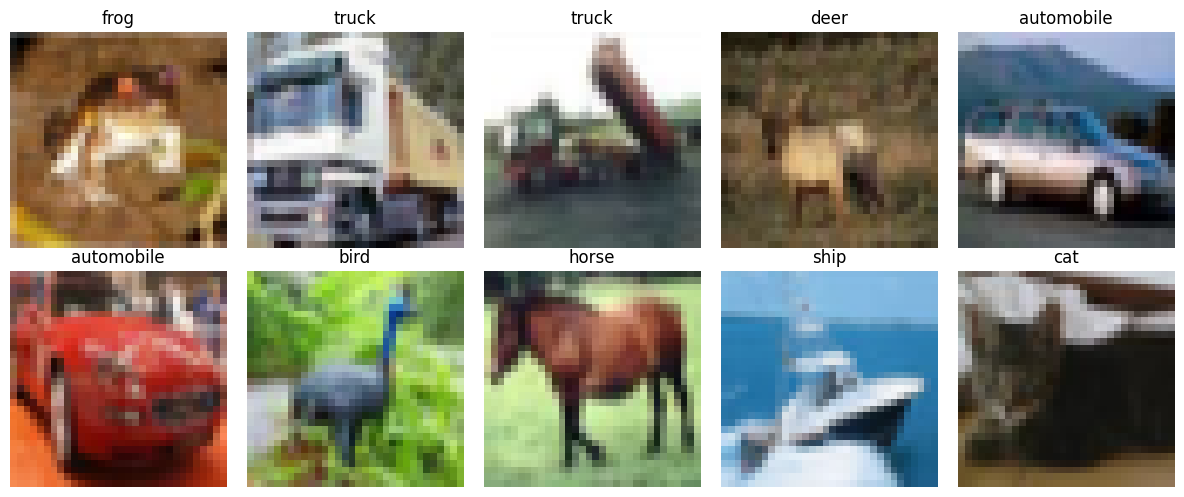

画像1枚のshape: torch.Size([3, 32, 32])
正解クラス: frog


In [26]:
def denormalize_image(image):
    mean = torch.tensor(
        CIFAR_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        CIFAR_STD
    ).view(3, 1, 1)

    image = image.cpu() * std + mean

    return image.clamp(0, 1)


plt.figure(figsize=(12, 5))

for i in range(10):
    image, label = train_plain_dataset[i]

    display_image = denormalize_image(
        image
    ).permute(1, 2, 0)

    plt.subplot(2, 5, i + 1)
    plt.imshow(display_image)
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

image, label = train_plain_dataset[0]

print("画像1枚のshape:", image.shape)
print("正解クラス:", class_names[label])


## 8. Data Augmentationの結果を見る

同じ元画像を複数回取り出しても、

- Cropする位置
- 左右反転するかどうか

がランダムに変わります。

これにより、モデルは元画像を暗記するのではなく、
位置や向きが少し変わっても認識できる特徴を学びやすくなります。


In [ ]:
sample_index = 12

plt.figure(figsize=(12, 5))

for i in range(10):
    augmented_image, label = (
        train_aug_dataset[sample_index]
    )

    display_image = denormalize_image(
        augmented_image
    ).permute(1, 2, 0)

    plt.subplot(2, 5, i + 1)
    plt.imshow(display_image)
    plt.title(class_names[label])
    plt.axis("off")

plt.suptitle(
    "同じ画像にData Augmentationを10回適用"
)
plt.tight_layout()
plt.show()


# PART 3 — 授業用の実行設定

## 9. FAST MODE

6種類のCNNをすべて学習するため、初期設定では授業用のFAST MODEを使います。

### FAST MODE

- 使用するTrain + Validation画像：15,000枚
- Validation：3,000枚
- 各実験：3 Epoch
- 最終モデル：4 Epoch

### FULL MODE

- Train + Validation：50,000枚
- Validation：5,000枚
- 各実験：10 Epoch
- 最終モデル：12 Epoch

> 最初は `FAST_MODE = True` のまま実行してください。


In [14]:
FAST_MODE = True

BATCH_SIZE = 128
LEARNING_RATE = 0.001

if FAST_MODE:
    TOTAL_SAMPLE_SIZE = 15_000
    VAL_SAMPLE_SIZE = 3_000
    EXPERIMENT_EPOCHS = 3
    FINAL_EPOCHS = 4
else:
    TOTAL_SAMPLE_SIZE = len(
        train_plain_dataset
    )
    VAL_SAMPLE_SIZE = 5_000
    EXPERIMENT_EPOCHS = 10
    FINAL_EPOCHS = 12

NUM_WORKERS = (
    2 if device.type == "cuda" else 0
)

print("FAST_MODE        :", FAST_MODE)
print("使用画像数       :", TOTAL_SAMPLE_SIZE)
print("Validation画像数 :", VAL_SAMPLE_SIZE)
print("各実験のEpoch数  :", EXPERIMENT_EPOCHS)
print("最終Epoch数      :", FINAL_EPOCHS)


FAST_MODE        : True
使用画像数       : 15000
Validation画像数 : 3000
各実験のEpoch数  : 3
最終Epoch数      : 4


## 10. Train / Validationを同じ条件で分ける

すべての改善実験を公平に比較するため、

- 使用する画像
- Train画像
- Validation画像

のindexを最初に1回だけ決めます。

各クラスの割合を保つため、`stratify` を使います。


In [15]:
all_indices = np.arange(
    len(train_plain_dataset)
)

all_targets = np.array(
    train_plain_dataset.targets
)

# FAST MODEでは50,000枚から一部を選ぶ
if TOTAL_SAMPLE_SIZE < len(
    train_plain_dataset
):
    selected_indices, _ = train_test_split(
        all_indices,
        train_size=TOTAL_SAMPLE_SIZE,
        stratify=all_targets,
        random_state=SEED
    )
else:
    selected_indices = all_indices

selected_targets = all_targets[
    selected_indices
]

# 同じTrain / Validation分割を
# すべての実験で使用する
train_indices, val_indices = (
    train_test_split(
        selected_indices,
        test_size=VAL_SAMPLE_SIZE,
        stratify=selected_targets,
        random_state=SEED
    )
)

print("Train画像数     :", len(train_indices))
print("Validation画像数:", len(val_indices))


NameError: name 'train_plain_dataset' is not defined

## 11. DataLoaderを作る関数

Data Augmentationを使う実験では `train_aug_dataset` を使い、
使わない実験では `train_plain_dataset` を使います。

Validationは、すべての実験で同じ通常画像を使います。


In [ ]:
def make_train_val_loaders(
    use_augmentation
):
    if use_augmentation:
        train_source = train_aug_dataset
    else:
        train_source = train_plain_dataset

    train_subset = Subset(
        train_source,
        train_indices
    )

    val_subset = Subset(
        train_plain_dataset,
        val_indices
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_subset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(
            device.type == "cuda"
        ),
        generator=generator
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=256,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(
            device.type == "cuda"
        )
    )

    return train_loader, val_loader


# PART 4 — 改善方法を切り替えられるCNN

## 12. 1つのモデルで複数の実験を行う

改善方法ごとに別々の長いModelクラスを書くと、違いが分かりにくくなります。

そこで、次の設定を切り替えられる `CIFARCNN` を作ります。

- `extra_conv`：Convolution Layerを追加するか
- `use_batch_norm`：Batch Normalizationを使うか
- `dropout_p`：Dropoutの確率

### 共通構造

```text
RGB Image
    ↓
Convolution Block 1
    ↓ Max Pool
Convolution Block 2
    ↓ Max Pool
Flatten
    ↓
Linear
    ↓
10 Classes
```


## 13. 改善方法の意味

### Convolution Layerを追加

1つのBlock内でConvolutionを2回行い、
より多段階の特徴を抽出します。

### Batch Normalization

中間のActivationをBatch単位で整え、
学習を安定させやすくします。

### Dropout

学習中に一部のNeuronをランダムに0にし、
特定のNeuronへの依存を減らします。

### Weight Decay

大きすぎるWeightを抑えるために、
Optimizerへ設定する正則化です。

Weight DecayはLayerではなく、後でOptimizerに設定します。


In [ ]:
class CIFARCNN(nn.Module):
    def __init__(
        self,
        extra_conv=False,
        use_batch_norm=False,
        dropout_p=0.0
    ):
        super().__init__()

        def make_block(
            in_channels,
            out_channels
        ):
            layers = [
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=3,
                    padding=1
                )
            ]

            if use_batch_norm:
                layers.append(
                    nn.BatchNorm2d(
                        out_channels
                    )
                )

            layers.append(nn.ReLU())

            # 改善①：Convolutionをもう1層追加
            if extra_conv:
                layers.append(
                    nn.Conv2d(
                        out_channels,
                        out_channels,
                        kernel_size=3,
                        padding=1
                    )
                )

                if use_batch_norm:
                    layers.append(
                        nn.BatchNorm2d(
                            out_channels
                        )
                    )

                layers.append(nn.ReLU())

            layers.append(
                nn.MaxPool2d(
                    kernel_size=2
                )
            )

            return layers

        self.features = nn.Sequential(
            # 3 × 32 × 32
            *make_block(3, 32),

            # 32 × 16 × 16
            *make_block(32, 64)

            # 出力：64 × 8 × 8
        )

        if dropout_p > 0:
            dropout_layer = nn.Dropout(
                p=dropout_p
            )
        else:
            dropout_layer = nn.Identity()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                64 * 8 * 8,
                128
            ),
            nn.ReLU(),

            # 改善④：Dropout
            dropout_layer,

            nn.Linear(
                128,
                10
            )
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)

        return x


## 14. Baselineモデルを確認する

Baselineでは、

- Convolution Layer：2層
- Data Augmentation：なし
- Batch Normalization：なし
- Dropout：なし
- Weight Decay：なし

です。

画像Batchを入力し、出力shapeが

```text
Batch × 10
```

になることを確認します。


In [ ]:
baseline_model = CIFARCNN(
    extra_conv=False,
    use_batch_norm=False,
    dropout_p=0.0
).to(device)

dummy_images = torch.randn(
    4, 3, 32, 32
).to(device)

with torch.no_grad():
    dummy_output = baseline_model(
        dummy_images
    )

print(baseline_model)
print("\n入力shape:", dummy_images.shape)
print("出力shape:", dummy_output.shape)


# PART 5 — 学習と評価の関数

## 15. 1 Epochを学習する

学習中は、

```python
model.train()
```

を使います。

Batch NormalizationとDropoutは、学習モードで動作します。


In [ ]:
def train_one_epoch(
    model,
    data_loader,
    optimizer,
    criterion,
    device
):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        optimizer.step()

        batch_size = images.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        predictions = logits.argmax(
            dim=1
        )

        total_correct += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    average_loss = (
        total_loss / total_samples
    )

    accuracy = (
        total_correct / total_samples
    )

    return average_loss, accuracy


## 16. Validation / Testを評価する

評価中はWeightを更新しないため、

```python
model.eval()
with torch.no_grad():
```

を使います。

`model.eval()` によって、

- Batch Normalization
- Dropout

も評価用の動作に切り替わります。


In [ ]:
def evaluate(
    model,
    data_loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

            batch_size = images.size(0)

            total_loss += (
                loss.item() * batch_size
            )

            predictions = logits.argmax(
                dim=1
            )

            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

    average_loss = (
        total_loss / total_samples
    )

    accuracy = (
        total_correct / total_samples
    )

    return average_loss, accuracy


## 17. 学習可能Parameter数を数える

Convolution Layerを追加すると、モデルのParameter数も増えます。

Parameter数が増えると、複雑な関係を学べる可能性がありますが、

- 計算時間が増える
- 過学習しやすくなる

という点にも注意が必要です。


In [ ]:
def count_trainable_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


## 18. 1つの改善実験を実行する関数

各実験について、次を同じ方法で実行します。

1. DataLoaderを作る
2. モデルを新しく作る
3. LossとOptimizerを作る
4. 指定Epoch数だけ学習する
5. Validation Accuracyが最も高かったWeightを保存する
6. 結果を返す

### Weight Decay

今回は全実験で `AdamW` を使い、

```python
weight_decay=0.0
```

または

```python
weight_decay=5e-4
```

を切り替えます。


In [ ]:
def run_experiment(
    config,
    experiment_number
):
    print("\n" + "=" * 75)
    print(
        f"Experiment {experiment_number}: "
        f"{config['name']}"
    )
    print("=" * 75)

    set_seed(SEED)

    train_loader, val_loader = (
        make_train_val_loaders(
            config["augmentation"]
        )
    )

    model = CIFARCNN(
        extra_conv=config["extra_conv"],
        use_batch_norm=config["batch_norm"],
        dropout_p=config["dropout_p"]
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=config["weight_decay"]
    )

    parameter_count = (
        count_trainable_parameters(model)
    )

    history = []

    best_val_accuracy = -1.0
    best_epoch = 0
    best_state = None

    start_time = time.time()

    for epoch in range(
        1,
        EXPERIMENT_EPOCHS + 1
    ):
        train_loss, train_accuracy = (
            train_one_epoch(
                model,
                train_loader,
                optimizer,
                criterion,
                device
            )
        )

        val_loss, val_accuracy = evaluate(
            model,
            val_loader,
            criterion,
            device
        )

        history.append({
            "Epoch": epoch,
            "Train Loss": train_loss,
            "Train Accuracy": train_accuracy,
            "Validation Loss": val_loss,
            "Validation Accuracy": val_accuracy
        })

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch

            best_state = {
                key: value.detach().cpu().clone()
                for key, value
                in model.state_dict().items()
            }

        print(
            f"Epoch {epoch:2d}/"
            f"{EXPERIMENT_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: "
            f"{train_accuracy * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: "
            f"{val_accuracy * 100:.2f}%"
        )

    elapsed_time = time.time() - start_time

    result = {
        "Experiment": experiment_number,
        "Name": config["name"],
        "Extra Conv": config["extra_conv"],
        "Augmentation": config["augmentation"],
        "BatchNorm": config["batch_norm"],
        "Dropout": config["dropout_p"],
        "Weight Decay": config["weight_decay"],
        "Parameters": parameter_count,
        "Best Epoch": best_epoch,
        "Best Validation Accuracy": (
            best_val_accuracy
        ),
        "Time (sec)": elapsed_time
    }

    return result, history, best_state


# PART 6 — 改善方法を1つずつ追加する

## 19. 実験の順番

今回の実験は **累積的** です。

後の実験ほど、それ以前の改善方法も含みます。

| 実験 | 追加する内容 |
|---|---|
| 1 | Baseline |
| 2 | + Convolution Layer |
| 3 | + Data Augmentation |
| 4 | + Batch Normalization |
| 5 | + Dropout |
| 6 | + Weight Decay |

この方法では、段階的にモデルがどう変化するかを観察できます。

ただし、厳密に1つだけの効果を測るAblation Studyではありません。


In [ ]:
EXPERIMENTS = [
    {
        "name": "1. Baseline",
        "extra_conv": False,
        "augmentation": False,
        "batch_norm": False,
        "dropout_p": 0.0,
        "weight_decay": 0.0
    },
    {
        "name": "2. + Extra Convolution",
        "extra_conv": True,
        "augmentation": False,
        "batch_norm": False,
        "dropout_p": 0.0,
        "weight_decay": 0.0
    },
    {
        "name": "3. + Data Augmentation",
        "extra_conv": True,
        "augmentation": True,
        "batch_norm": False,
        "dropout_p": 0.0,
        "weight_decay": 0.0
    },
    {
        "name": "4. + Batch Normalization",
        "extra_conv": True,
        "augmentation": True,
        "batch_norm": True,
        "dropout_p": 0.0,
        "weight_decay": 0.0
    },
    {
        "name": "5. + Dropout",
        "extra_conv": True,
        "augmentation": True,
        "batch_norm": True,
        "dropout_p": 0.3,
        "weight_decay": 0.0
    },
    {
        "name": "6. + Weight Decay",
        "extra_conv": True,
        "augmentation": True,
        "batch_norm": True,
        "dropout_p": 0.3,
        "weight_decay": 5e-4
    }
]

display(
    pd.DataFrame(EXPERIMENTS)
)


## 20. 6つの実験を実行する

このセルは、GPUでも数分程度かかる場合があります。

実行中は、各実験のEpochごとにTrain / Validation結果が表示されます。

> 結果が必ず実験番号順に向上するとは限りません。  
> Data Augmentationや正則化は、短いEpochではTrain Accuracyを下げることもあります。


In [ ]:
experiment_results = []
experiment_histories = {}
experiment_best_states = {}

for experiment_number, config in enumerate(
    EXPERIMENTS,
    start=1
):
    result, history, best_state = (
        run_experiment(
            config,
            experiment_number
        )
    )

    experiment_results.append(result)

    experiment_histories[
        config["name"]
    ] = pd.DataFrame(history)

    experiment_best_states[
        config["name"]
    ] = best_state

results_df = pd.DataFrame(
    experiment_results
)

print("\nすべての実験が完了しました。")


# PART 7 — 性能変化を比較する

## 21. 結果表

比較するときは、まず **Best Validation Accuracy** を見ます。

Test Accuracyは、この段階ではまだ使いません。


In [ ]:
display_columns = [
    "Experiment",
    "Name",
    "Parameters",
    "Best Epoch",
    "Best Validation Accuracy",
    "Time (sec)"
]

comparison_df = results_df[
    display_columns
].copy()

comparison_df[
    "Best Validation Accuracy (%)"
] = (
    comparison_df[
        "Best Validation Accuracy"
    ] * 100
)

display(
    comparison_df[
        [
            "Experiment",
            "Name",
            "Parameters",
            "Best Epoch",
            "Best Validation Accuracy (%)",
            "Time (sec)"
        ]
    ].round(2)
)


## 22. Validation Accuracyを棒グラフで比較する

どの改善段階でValidation Accuracyが変化したか確認します。


In [ ]:
plot_df = comparison_df.copy()

plt.figure(figsize=(12, 5))

bars = plt.bar(
    plot_df["Name"],
    plot_df[
        "Best Validation Accuracy (%)"
    ]
)

plt.ylabel(
    "Best Validation Accuracy (%)"
)
plt.title(
    "CIFAR-10: CNN Performance Improvement"
)
plt.xticks(
    rotation=25,
    ha="right"
)

for bar, value in zip(
    bars,
    plot_df[
        "Best Validation Accuracy (%)"
    ]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{value:.1f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


## 23. EpochごとのValidation Accuracyを見る

棒グラフは最良の結果だけを示します。

次のグラフでは、

- 学習がどのように進んだか
- 何Epoch目でValidation Accuracyが高くなったか
- 学習が不安定ではないか

を確認します。


In [ ]:
plt.figure(figsize=(11, 6))

for name, history_df in (
    experiment_histories.items()
):
    plt.plot(
        history_df["Epoch"],
        history_df[
            "Validation Accuracy"
        ] * 100,
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title(
    "Validation Accuracy by Epoch"
)
plt.xticks(
    range(
        1,
        EXPERIMENT_EPOCHS + 1
    )
)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 24. TrainとValidationの差を見る

過学習の手がかりとして、

```text
Train Accuracy − Validation Accuracy
```

を確認します。

差が大きい場合、学習データにはよく合っていても、
未知データでは性能が低い可能性があります。


In [ ]:
gap_rows = []

for name, history_df in (
    experiment_histories.items()
):
    best_row_index = (
        history_df[
            "Validation Accuracy"
        ].idxmax()
    )

    best_row = history_df.loc[
        best_row_index
    ]

    gap_rows.append({
        "Name": name,
        "Train Accuracy (%)": (
            best_row[
                "Train Accuracy"
            ] * 100
        ),
        "Validation Accuracy (%)": (
            best_row[
                "Validation Accuracy"
            ] * 100
        ),
        "Train - Validation Gap": (
            (
                best_row[
                    "Train Accuracy"
                ]
                - best_row[
                    "Validation Accuracy"
                ]
            ) * 100
        )
    })

gap_df = pd.DataFrame(gap_rows)

display(
    gap_df.round(2)
)


# PART 8 — Validationで最良の設定を選ぶ

## 25. 最良の実験を選ぶ

Validation Accuracyが最も高かった設定を選びます。

Test結果を見てからモデルを選ぶのではありません。

```text
Train：Weightを学習
Validation：設定やモデルを比較
Test：最後の最終評価
```


In [ ]:
best_result_index = results_df[
    "Best Validation Accuracy"
].idxmax()

best_result = results_df.loc[
    best_result_index
]

best_experiment_number = int(
    best_result["Experiment"]
)

best_config = EXPERIMENTS[
    best_experiment_number - 1
]

print("最良の実験:")
print(best_result["Name"])

print(
    "Best Validation Accuracy:",
    f"{best_result['Best Validation Accuracy'] * 100:.2f}%"
)

print("\n選ばれた設定:")
print(best_config)


# PART 9 — 最終モデルを作り、Testで1回だけ評価する

## 26. Train + Validationをすべて使う

設定を選び終えたので、新しいモデルを最初から作ります。

今度は、実験で使ったTrainとValidationを合わせたすべての画像で学習します。

```text
選択済みのTrain + Validation
        ↓
新しい最終モデルを学習
        ↓
Testで1回だけ最終評価
```


In [ ]:
# 最良設定に合わせて
# Augmentationあり / なしを選ぶ
if best_config["augmentation"]:
    final_train_source = (
        train_aug_dataset
    )
else:
    final_train_source = (
        train_plain_dataset
    )

final_train_dataset = Subset(
    final_train_source,
    selected_indices
)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(
        device.type == "cuda"
    )
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(
        device.type == "cuda"
    )
)

print(
    "最終学習画像数:",
    len(final_train_dataset)
)
print(
    "Test画像数:",
    len(test_dataset)
)


## 27. 最終モデルを学習する

Validation比較に使ったモデルをそのままTestするのではなく、
選ばれた設定で新しいモデルを作り直します。


In [ ]:
set_seed(SEED)

final_model = CIFARCNN(
    extra_conv=best_config["extra_conv"],
    use_batch_norm=best_config[
        "batch_norm"
    ],
    dropout_p=best_config["dropout_p"]
).to(device)

final_criterion = nn.CrossEntropyLoss()

final_optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=best_config[
        "weight_decay"
    ]
)

final_history = []

for epoch in range(
    1,
    FINAL_EPOCHS + 1
):
    train_loss, train_accuracy = (
        train_one_epoch(
            final_model,
            final_train_loader,
            final_optimizer,
            final_criterion,
            device
        )
    )

    final_history.append({
        "Epoch": epoch,
        "Train Loss": train_loss,
        "Train Accuracy": train_accuracy
    })

    print(
        f"Epoch {epoch:2d}/"
        f"{FINAL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: "
        f"{train_accuracy * 100:.2f}%"
    )


## 28. Test Accuracyを測定する

このセルで、初めてTestデータを評価します。


In [ ]:
test_loss, test_accuracy = evaluate(
    final_model,
    test_loader,
    final_criterion,
    device
)

print("Test Loss    :", round(test_loss, 4))
print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)


# PART 10 — 最終モデルの間違い方を確認する

## 29. 予測結果を集める


In [ ]:
def collect_predictions(
    model,
    data_loader,
    device
):
    model.eval()

    all_images = []
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            logits = model(
                images.to(device)
            )

            predictions = logits.argmax(
                dim=1
            ).cpu()

            all_images.append(
                images.cpu()
            )
            all_labels.append(
                labels.cpu()
            )
            all_predictions.append(
                predictions
            )

    return (
        torch.cat(all_images),
        torch.cat(all_labels),
        torch.cat(all_predictions)
    )

test_images, test_labels, test_predictions = (
    collect_predictions(
        final_model,
        test_loader,
        device
    )
)

print("画像:", test_images.shape)
print("正解:", test_labels.shape)
print("予測:", test_predictions.shape)


## 30. Confusion Matrix

- 行：実際のクラス
- 列：予測したクラス
- 対角線：正解
- 対角線以外：誤分類

CIFAR-10では、例えばcatとdog、automobileとtruckなどが混同される場合があります。
実際の結果を見て確認してください。


In [ ]:
cm = confusion_matrix(
    test_labels.numpy(),
    test_predictions.numpy(),
    labels=list(range(10))
)

fig, ax = plt.subplots(
    figsize=(10, 9)
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_cm.plot(
    ax=ax,
    xticks_rotation=45,
    colorbar=False
)

plt.title(
    "CIFAR-10 Confusion Matrix"
)
plt.tight_layout()
plt.show()


## 31. 間違えた画像を見る

画像が小さく背景も複雑なので、人間にも判断しにくい画像があります。

誤分類画像を見ながら、

- 画像がぼやけていないか
- 対象物が小さくないか
- 別のクラスに似ていないか
- 背景に影響されていないか

を考えてみましょう。


In [ ]:
wrong_positions = torch.where(
    test_labels != test_predictions
)[0]

print(
    "間違えた画像数:",
    len(wrong_positions)
)

show_count = min(
    12,
    len(wrong_positions)
)

set_seed(SEED)

selected_wrong_positions = (
    wrong_positions[
        torch.randperm(
            len(wrong_positions)
        )[:show_count]
    ]
)

plt.figure(figsize=(14, 8))

for i, position in enumerate(
    selected_wrong_positions
):
    image = denormalize_image(
        test_images[position]
    ).permute(1, 2, 0)

    actual = class_names[
        test_labels[position].item()
    ]

    predicted = class_names[
        test_predictions[position].item()
    ]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


# 改善方法のまとめ

## Convolution Layerを追加

- より多段階の特徴抽出ができる
- Parameter数と計算量が増える
- 深くすれば必ず良くなるわけではない

## Data Augmentation

- Train画像をランダムに変形する
- 見かけ上のデータ多様性を増やす
- Validation / Testには適用しない

## Batch Normalization

- 中間ActivationをBatch単位で整える
- 学習を安定させやすい
- `model.train()` と `model.eval()` で動作が変わる

## Dropout

- 学習中に一部のNeuronをランダムに無効化する
- 特定のNeuronへの依存を減らす
- 評価時には自動的に無効になる

## Weight Decay

- 大きすぎるWeightを抑える
- Optimizerの設定として使用する
- 過学習を抑えるための正則化


# 確認問題

実行結果を見ながら答えてください。

### Q1
MNISTとCIFAR-10の画像shapeはどのように違いますか。

### Q2
Baseline CNNのBest Validation Accuracyは何％でしたか。

### Q3
Convolution Layerを追加すると、Parameter数とValidation Accuracyはどう変わりましたか。

### Q4
Data Augmentationでは、どの画像変換を使いましたか。

### Q5
Data AugmentationをValidation / Testに適用しない理由を説明してください。

### Q6
Batch Normalizationを追加したとき、Validation Accuracyはどう変化しましたか。

### Q7
DropoutとWeight Decayは、何を防ぐための方法ですか。

### Q8
6つの実験の中で、Validation Accuracyが最も高かったのはどの設定でしたか。

### Q9
最終モデルのTest Accuracyは何％でしたか。

### Q10
Confusion Matrixから、間違えやすかったクラスの組み合わせを1つ挙げてください。

### Q11
改善手法を追加しても、Accuracyが必ず順番に上がるとは限らない理由を考えてください。


# 発展実験

時間に余裕がある場合は、次のうち1つだけ変更してください。

- `EXPERIMENT_EPOCHS` を増やす
- Dropoutを `0.3 → 0.5` に変更する
- Weight Decayを `5e-4 → 1e-4` に変更する
- Filter数を `32, 64 → 64, 128` に変更する
- Learning Rateを変更する

複数の条件を同時に変更すると、どの変更が結果に影響したのか分かりにくくなります。

**1回の実験では1つだけ変更する**ことが基本です。


## 参考

- torchvision CIFAR10 Dataset
- torchvision transforms
- PyTorch `nn.BatchNorm2d`
- PyTorch `nn.Dropout`
- PyTorch `torch.optim.AdamW`

このノートブックでは、CNNの改善方法による性能変化を比較しやすくするため、
モデルと実験条件を単純化しています。
